# Лабораторна робота №7
**Виконав:** Карпенко Артем Олександрович, Варіант 3

**Мета роботи:** Ознайомитися з бібліотекою Matplotlib у Python, навчитися будувати графіки функцій, форматувати їх, знаходити точки перетину ліній та зафарбовувати області розв'язку.

**Завдання за варіантом:**
Потрібно розв'язати графічним методом наступну систему лінійних нерівностей:
$$
\begin{cases}
3x + y \ge 6 \\
x + y \le 8 \\
x \ge 1
\end{cases}
$$

### 1. Побудова окремих графіків
**По завданню треба було** побудувати три прямі лінії з нашої системи на трьох окремих графіках, але розмістити їх поруч. Графіки повинні мати спільну вертикальну вісь (вісь Y), відрізнятися кольорами та стилями ліній, мати сітку, підписи осей та красиві назви рівнянь.

**Для реалізації ми використали** бібліотеки `numpy` (для створення масиву точок) та `matplotlib.pyplot` (для малювання). Щоб побудувати три графіки поруч, ми застосували функцію `subplots`, вказавши спільну вісь Y. Далі ми виразили $y$ з кожного рівняння ($y = 6 - 3x$ та $y = 8 - x$) і намалювали їх функцією `plot`. Для третього рівняння ($x = 1$) ми використали спеціальну функцію `axvline`, яка малює вертикальну лінію. Назви графіків ми відформатували у LaTeX, щоб вони виглядали як справжні математичні формули, і зберегли результат як картинку.

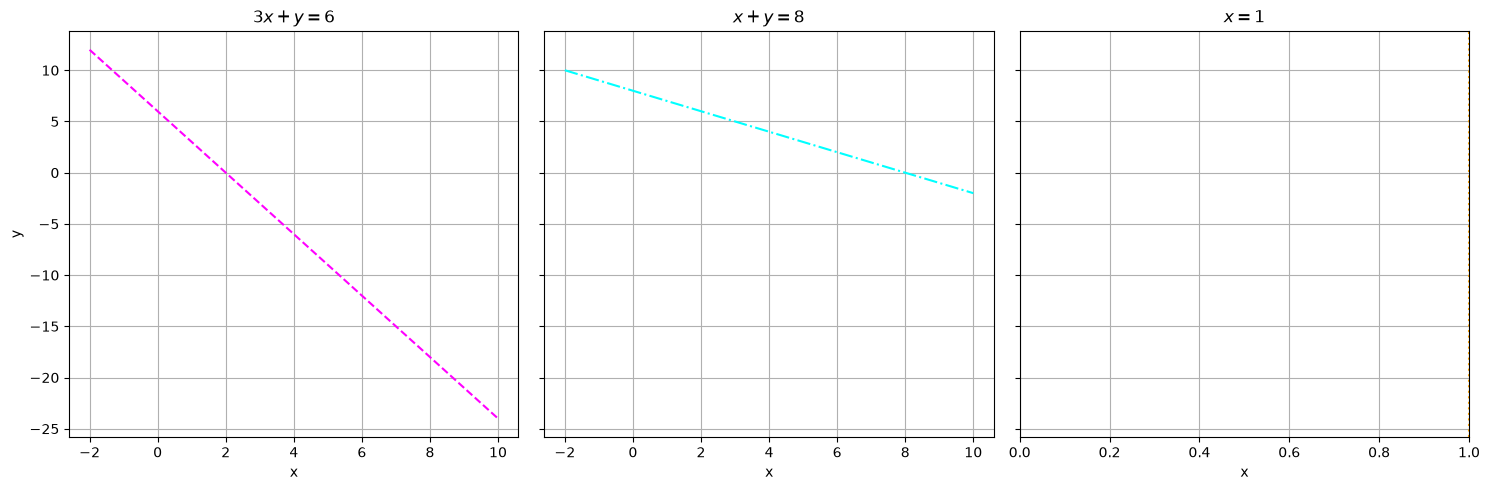

In [2]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 10, 400)
y1 = 6 - 3 * x
y2 = 8 - x

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

axes[0].plot(x, y1, color='magenta', linestyle='--', label=r'$3x + y = 6$')
axes[0].set_title(r'$3x + y = 6$')
axes[0].grid(True)
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')

axes[1].plot(x, y2, color='cyan', linestyle='-.', label=r'$x + y = 8$')
axes[1].set_title(r'$x + y = 8$')
axes[1].grid(True)
axes[1].set_xlabel('x')

axes[2].axvline(x=1, color='orange', linestyle=':', label=r'$x = 1$')
axes[2].set_title(r'$x = 1$')
axes[2].grid(True)
axes[2].set_xlabel('x')

plt.tight_layout()
plt.savefig('subplots.png')
plt.show()

### 2. Побудова спільного графіка та зафарбовування області розв'язку
**По завданню треба було** об'єднати всі три лінії на одному графіку, програмно знайти координати точок їх перетину, відмітити ці точки та зафарбувати область, яка є розв'язком нашої системи нерівностей.

**Для реалізації ми використали** підмодуль `numpy.linalg`, щоб знайти точки перетину. Для кожної пари ліній ми створили матрицю коефіцієнтів та розв'язали систему рівнянь. Потім ми побудували всі три прямі на одному полотні, а знайдені точки перетину відмітили червоними кружечками. Щоб підписати рівняння прямо біля ліній під потрібним кутом, ми застосували функцію `text`. Для зафарбовування області розв'язку ми використали функцію `fill_between`, вказавши їй обмеження: замалювати зону починаючи від $x=1$, яка лежить вище лінії $3x+y=6$ та водночас нижче лінії $x+y=8$.

Точки перетину ліній:
1 і 2: [-1.  9.]
1 і 3: [1. 3.]
2 і 3: [1. 7.]


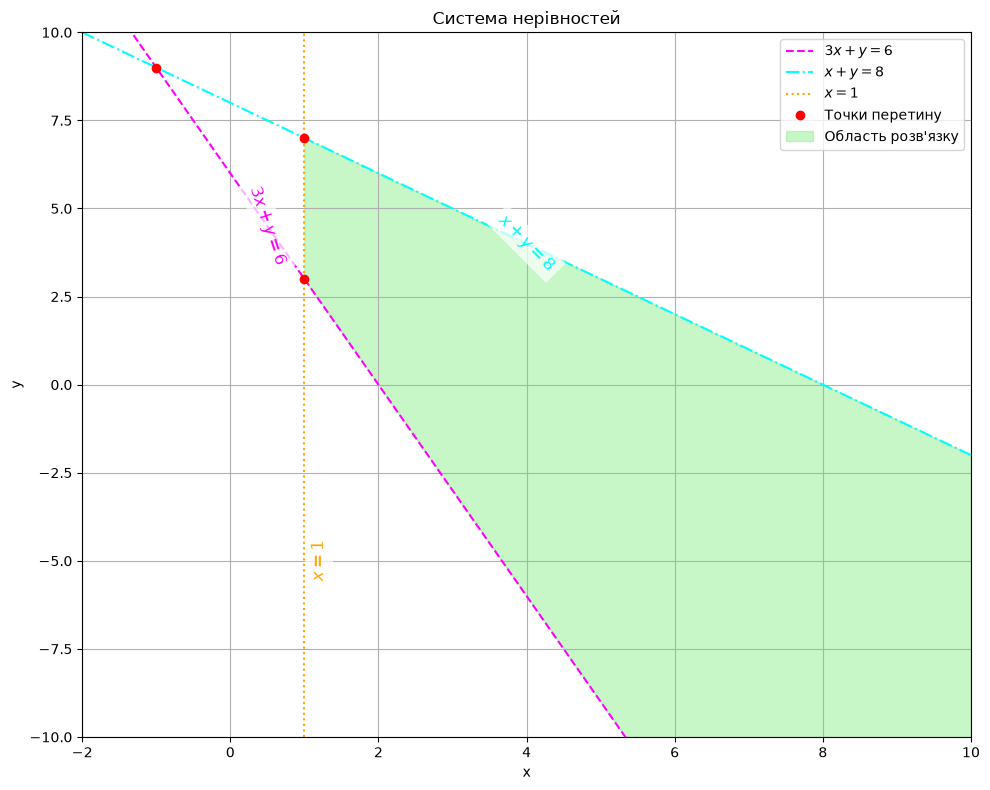

In [3]:
A12 = np.array([[3, 1], [1, 1]])
b12 = np.array([6, 8])
pt12 = np.linalg.solve(A12, b12)

A13 = np.array([[3, 1], [1, 0]])
b13 = np.array([6, 1])
pt13 = np.linalg.solve(A13, b13)

A23 = np.array([[1, 1], [1, 0]])
b23 = np.array([8, 1])
pt23 = np.linalg.solve(A23, b23)

print("Точки перетину ліній:")
print(f"1 і 2: {pt12}")
print(f"1 і 3: {pt13}")
print(f"2 і 3: {pt23}")

fig, ax = plt.subplots(figsize=(10, 8))

ax.plot(x, y1, color='magenta', linestyle='--', label=r'$3x + y = 6$')
ax.plot(x, y2, color='cyan', linestyle='-.', label=r'$x + y = 8$')
ax.axvline(x=1, color='orange', linestyle=':', label=r'$x = 1$')

ax.plot(pt12[0], pt12[1], 'ro', label='Точки перетину')
ax.plot(pt13[0], pt13[1], 'ro')
ax.plot(pt23[0], pt23[1], 'ro')

x_fill = np.linspace(1, 10, 400)
y1_fill = 6 - 3 * x_fill
y2_fill = 8 - x_fill
y_bottom = np.maximum(y1_fill, -10)
ax.fill_between(x_fill, y_bottom, y2_fill, where=(y2_fill >= y1_fill), color='lightgreen', alpha=0.5, label='Область розв\'язку')

ax.text(0.5, 4.5, r'$3x + y = 6$', rotation=-71, color='magenta', fontsize=12, ha='center', va='center', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
ax.text(4, 4, r'$x + y = 8$', rotation=-45, color='cyan', fontsize=12, ha='center', va='center', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
ax.text(1.2, -5, r'$x = 1$', rotation=90, color='orange', fontsize=12, ha='center', va='center', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

ax.set_xlim(-2, 10)
ax.set_ylim(-10, 10)
ax.grid(True)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Система нерівностей')
ax.legend()

plt.tight_layout()
plt.savefig('combined_plot.png')
plt.show()

### Висновки
Під час виконання лабораторної роботи ми навчилися використовувати бібліотеку `matplotlib` для візуалізації математичних рівнянь. Ми побудували окремі графіки з суміщеною віссю Y та спільний графік, що показує взаємне розташування прямих. Завдяки модулю `numpy.linalg` ми швидко розв'язали системи лінійних рівнянь матричним методом і знайшли точні координати точок перетину, не рахуючи їх вручну. Використання функції `fill_between` дозволило програмно виділити на графіку ту зону, яка задовольняє всі умови нашої системи нерівностей.